In [ ]:
from collections.abc import Iterable
from cryoswath import misc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray as rioxr
import seaborn as sns
from textwrap import dedent, wrap
from cryoswath_paper_workflow.workflow_support import to_yaml
import xarray as xr

In [42]:
cs2: xr.Dataset = rioxr.open_rasterio(snakemake.input["own"], band_as_variable=True)  # pyright: ignore[reportAssignmentType]
cs2 = cs2.rename_vars({k: v.attrs["short_name"] for k, v in cs2.data_vars.items()})

In [43]:
basins = misc.load_glacier_outlines("06-01", "basins", union=False, crs=cs2.rio.crs)
cmplxs = misc.load_glacier_outlines("06-01", union=False, crs=cs2.rio.crs)
vatna = cmplxs.sort_values("area_km2", ascending=False).iloc[[0]]  # pyright: ignore[reportAttributeAccessIssue]

/home/jan/figures-from-scratch-test/.pixi/envs/cryoswath022/lib/python3.13/site-packages/cryoswath/misc.py:407: UserWarning: Dropping 232 glaciers < 1 km² from RGI o1 region.
  warnings.warn(


In [44]:
hugonnet = rioxr.open_rasterio(
    snakemake.input["ref"], mask_and_scale=True, band_as_variable=True
).band_1.rename("ref")  # pyright: ignore[reportAttributeAccessIssue]

In [45]:
# write out raw difference for Figure 15c
(cs2.trend - hugonnet).assign_attrs(
    long_name="trend difference", units="m/yr"
).rio.to_raster(snakemake.output["diff_raster"])

In [46]:
diff = cs2.trend.fillna(0) - hugonnet.fillna(0)

In [47]:
def _any(masks: Iterable[xr.DataArray]) -> xr.DataArray:
    return False if not masks else xr.concat(masks, "tmp").any("tmp")  # pyright: ignore[reportReturnType]

In [ ]:
def explained_by_mask(mask: xr.DataArray) -> float:
    return diff.where(mask).sum().item() * 500**2 * 0.85 / 1e9

In [49]:
mask_stack = dict()

In [50]:
def add_mask(name: str, mask: xr.DataArray):
    # global mask_stack
    mask_stack[name] = mask.astype("bool")
    print(mask_stack.keys())
    print(
        "Explained by current stack:",
        "{:.2f}".format(explained_by_mask(_any(mask_stack.values()))),  # pyright: ignore[reportArgumentType]
        "Gt/yr",
    )

In [51]:
add_mask("outside", hugonnet.rio.clip(vatna.geometry).isnull())

dict_keys(['outside'])
Explained by current stack: 0.09 Gt/yr


In [52]:
add_mask("coverage", cs2.trend.isnull() & hugonnet.notnull())

dict_keys(['outside', 'coverage'])
Explained by current stack: 0.64 Gt/yr


In [53]:
add_mask("interp", cs2.interp_flag > 0)

dict_keys(['outside', 'coverage', 'interp'])
Explained by current stack: 1.41 Gt/yr


In [54]:
quantiles = diff.where(~_any(mask_stack.values())).quantile(
    [0.05, 0.95]
)  # only considers observed values
add_mask(
    "tails",
    (diff < quantiles.sel(quantile=0.05)) | (diff > quantiles.sel(quantile=0.95)),
)

dict_keys(['outside', 'coverage', 'interp', 'tails'])
Explained by current stack: 1.65 Gt/yr


In [55]:
def row(i: int):
    mass_diff = explained_by_mask(
        _any(list(mask_stack.values())[: i + 1])
    ) - explained_by_mask(_any(list(mask_stack.values())[:i]))
    return mass_diff, mass_diff / explained_by_mask(True)


df = pd.DataFrame.from_dict(
    {k: row(i) for i, k in enumerate(mask_stack)},
    orient="index",
    columns=["mass", "ratio"],
)
df.to_csv(snakemake.output["expl_tbl"])
df

,mass,ratio
outside,0.088638,0.025656
coverage,0.554843,0.160600
interp,0.761880,0.220527
tails,0.244172,0.070676


Figure not in main text (replaced by QGIS-produced equivalent).
The plot compares all trend differences (left) including grid cells
outside the glacier and those exclude because they were presumed to be
mostly ice-free, and only the cells that are not masked by any of the
previously defined criteria (and, hence, must explain the remaining
52%).


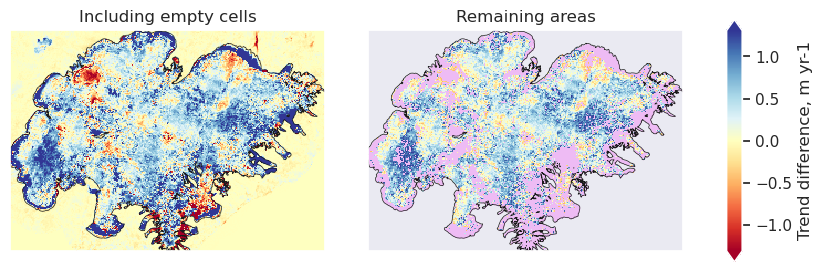

In [56]:
print("Figure not in main text (replaced by QGIS-produced equivalent).")
legend = f"""\
    The plot compares all trend differences (left) including grid cells
    outside the glacier and those exclude because they were presumed to
    be mostly ice-free, and only the cells that are not masked by any of
    the previously defined criteria (and, hence, must explain the
    remaining {1 - df.ratio.sum():.0%})."""
print(*wrap(dedent(legend)), sep="\n")
cbar_max = np.abs(diff.where(~_any(mask_stack.values()))).max().item()
fig, ax = plt.subplots(
    ncols=3, width_ratios=[1, 1, 0.05], figsize=(24 / 2.54, 8 / 2.54)
)
map = diff.plot(
    ax=ax[0],
    cmap="RdYlBu",
    vmin=-cbar_max,
    vmax=cbar_max,
    cbar_ax=ax[2],
    cbar_kwargs={"label": "Trend difference, m yr-1"},
)
vatna.boundary.plot(ax=ax[0], color="k", lw=0.5)
ax[0].set_title("Including empty cells")
vatna.plot(ax=ax[1], fc="magenta", alpha=0.2, lw=0.5)  # ec="k",
diff.where(~_any(mask_stack.values())).plot(
    ax=ax[1], cmap="RdYlBu", vmin=-cbar_max, vmax=cbar_max, add_colorbar=False
)
vatna.boundary.plot(ax=ax[1], color="k", lw=0.5)
ax[1].set_title("Remaining areas")
for x in ax[:2]:
    x.xaxis.set_visible(False)
    x.yaxis.set_visible(False)

In [57]:
sns.set_theme()

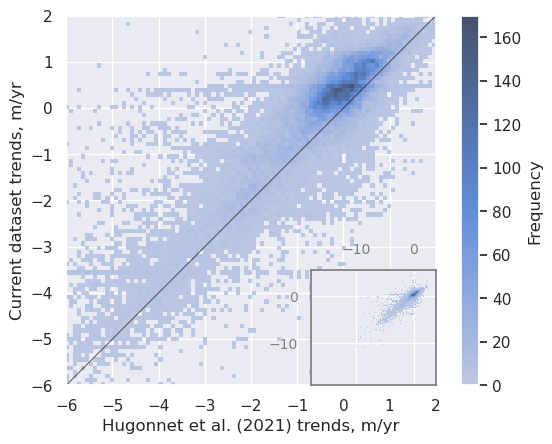

In [58]:
all_cs2_mask = ~_any([mask_stack["outside"], mask_stack["coverage"]])
limits = [-6, 2]
sns.histplot(
    y=cs2.trend.where(all_cs2_mask)
    .to_series()
    .dropna()
    .rename("Current dataset trends, m/yr"),
    x=hugonnet.where(all_cs2_mask)
    .to_series()
    .dropna()
    .rename("Hugonnet et al. (2021) trends, m/yr"),
    cbar=True,
    cbar_kws={"label": "Frequency"},
)
main = plt.gca()
plt.plot([0, 1], [0, 1], transform=main.transAxes, c="k", lw=0.5)
plt.xlim(limits)
plt.ylim(limits)
main.set_aspect("equal")
fig = plt.gcf()
bbox = main.get_position()
bbox.x0 = 0.55
bbox.y1 = 0.35
inset = fig.add_axes(bbox)
sns.histplot(
    ax=inset,
    y=cs2.trend.where(all_cs2_mask)
    .to_series()
    .dropna()
    .rename("Current dataset trends, m/yr"),
    x=hugonnet.where(all_cs2_mask)
    .to_series()
    .dropna()
    .rename("Hugonnet et al. (2021) trends, m/yr"),
    cbar=False,
)
inset.set(xlabel="", ylabel="")
inset.tick_params(labeltop=True, labelbottom=False, labelsize=10, labelcolor="tab:gray")
for sp in inset.spines.values():
    sp.set_edgecolor("tab:gray")
plt.savefig(snakemake.output["fig15"])

In [ ]:
to_yaml(
    {
        "cs2": {
            "value": float(cs2.trend.sum()) * 500**2 * 0.85 / 1e9,
            "units": ["Gt", "yr^{-1}"],
        },
        "ref": {
            "value": float(hugonnet.sum()) * 500**2 * 0.85 / 1e9,
            "units": ["Gt", "yr^{-1}"],
        },
        "diff": {
            "value": explained_by_mask(True),
            "units": ["Gt", "yr^{-1}"],
        },
        "remain": {
            "value": float(diff.where(~_any(mask_stack.values())).mean()),
            "units": ["m", "yr^{-1}"],
        },
        "clipped_ratio": {
            "value": 100 * float((diff != diff.clip(*limits)).where(all_cs2_mask).mean()),
            "units": ["\%"],
        },
    },
    snakemake.output["vals"],
)

<>:22: SyntaxWarning: invalid escape sequence '\%'
<>:22: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_1158820/3691935048.py:22: SyntaxWarning: invalid escape sequence '\%'
  "units": ["\%"],
/tmp/ipykernel_1158820/3691935048.py:22: SyntaxWarning: invalid escape sequence '\%'
  "units": ["\%"],


RepresenterError: ('cannot represent an object', <xarray.DataArray 'ref' (y: 200, x: 285)> Size: 456kB
array([[inf, inf, inf, ..., inf, inf, inf],
       [inf, inf, inf, ..., inf, inf, inf],
       [inf, inf, inf, ..., inf, inf, inf],
       ...,
       [inf, inf, inf, ..., inf, inf, inf],
       [inf, inf, inf, ..., inf, inf, inf],
       [inf, inf, inf, ..., inf, inf, inf]], shape=(200, 285))
Coordinates:
  * x            (x) float64 2kB 3.472e+05 3.478e+05 ... 4.888e+05 4.892e+05
  * y            (y) float64 2kB 7.091e+06 7.092e+06 ... 7.19e+06 7.191e+06
    spatial_ref  int64 8B 0)